# RSNA Knee - 데이터 EDA

CSV만 본다
DICOM은 Kaggle에만 있으므로 여기서는 건드리지 않는다

텍스트 요약본은 `docs/eda.md` 에 있다


In [1]:
import sys, re
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

import config, paths

# 한글 폰트 (없으면 기본값 유지)
for _f in ['AppleGothic', 'Apple SD Gothic Neo', 'NanumGothic', 'Malgun Gothic']:
    if _f in {f.name for f in mpl.font_manager.fontManager.ttflist}:
        mpl.rcParams['font.family'] = _f
        break
mpl.rcParams['axes.unicode_minus'] = False

mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['font.size'] = 9
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.3
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

L = list(config.LABELS)
print(paths.describe())
print('labels:', L)


[Local] DATA_DIR=/Users/hyejin/Knee_Detection/data (exists=True)
        OUTPUT_DIR=/Users/hyejin/Knee_Detection/outputs
labels: ['ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture']


## 1. 파일 개요


In [2]:
train = pd.read_csv(paths.TRAIN_CSV)
tr_series = pd.read_csv(paths.DATA_DIR / 'train_series.csv')
te_series = pd.read_csv(paths.DATA_DIR / 'test_series.csv')
test = pd.read_csv(paths.DATA_DIR / 'test.csv')
sub = pd.read_csv(paths.SAMPLE_SUBMISSION_CSV)

config.verify_labels()   # 제출 컬럼 순서 검증

pd.DataFrame([
    ['train.csv', *train.shape, '스터디 단위 레이블 + 판독문'],
    ['train_series.csv', *tr_series.shape, '시리즈 단위 메타데이터'],
    ['test.csv', *test.shape, '공개용 placeholder (실채점은 hidden rerun)'],
    ['test_series.csv', *te_series.shape, '동일'],
    ['sample_submission.csv', *sub.shape, '제출 형식'],
], columns=['파일', '행', '열', '설명'])


,파일,행,열,설명
0,train.csv,4407,14,스터디 단위 레이블 + 판독문
1,train_series.csv,24371,5,시리즈 단위 메타데이터
2,test.csv,3,1,공개용 placeholder (실채점은 hidden rerun)
3,test_series.csv,15,5,동일
4,sample_submission.csv,3,13,제출 형식


In [3]:
train.head(3)


,StudyInstanceUID,Report,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,Técnica: RMN de la rodilla. Resultados: Rotura...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.2.826.0.1.3680043.8.498.10004945927472656027...,[DATE]: * MR Knie Rechts 15ch AA Klinische Inl...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1.2.826.0.1.3680043.8.498.10009278692606631573...,Hallazgos:\nNo hay alteraciones en significati...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. 레이블 희소성

이 대회의 핵심
레이블이 있는 스터디가 몇 개인지 먼저 본다


In [4]:
lab = train[L]
has_label = lab.notna().any(axis=1)
n_gold = int(has_label.sum())

print(f'레이블 보유 스터디: {n_gold} / {len(train):,}  ({n_gold/len(train)*100:.2f}%)')
print()
print('스터디당 채워진 레이블 개수:')
print(lab.notna().sum(axis=1).value_counts().sort_index().to_string())


레이블 보유 스터디: 58 / 4,407  (1.32%)

스터디당 채워진 레이블 개수:
0     4349
12      58


In [5]:
gold = train.loc[has_label, L]

stat = pd.DataFrame({
    '양성': gold.eq(1).sum(),
    '음성': gold.eq(0).sum(),
})
stat['양성률'] = stat['양성'] / (stat['양성'] + stat['음성'])
stat = stat.loc[L]
stat


,양성,음성,양성률
ACL,24,34,0.413793
MCL,9,49,0.155172
Medial Meniscus,26,32,0.448276
Lateral Meniscus,23,35,0.396552
Medial OA,15,43,0.258621
Lateral OA,11,47,0.189655
PF OA,21,37,0.362069
Effusion,35,23,0.603448
Synovitis,27,31,0.465517
Baker's,12,46,0.206897


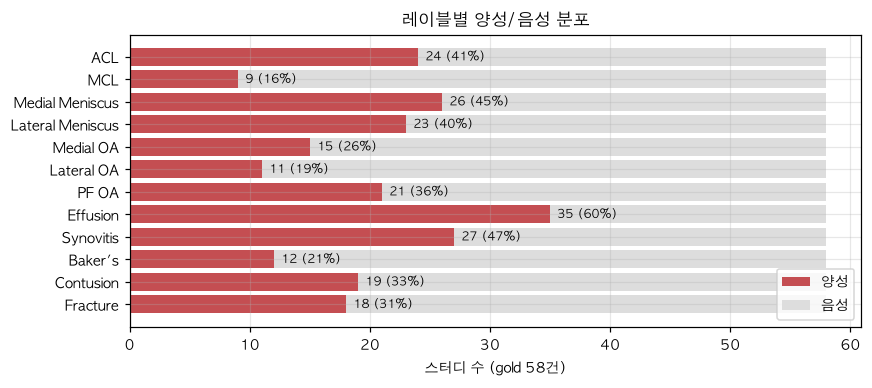

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(L))[::-1]
ax.barh(y, stat['양성'], color='#c44e52', label='양성')
ax.barh(y, stat['음성'], left=stat['양성'], color='#dddddd', label='음성')
ax.set_yticks(y); ax.set_yticklabels(L)
for i, (p, r) in enumerate(zip(stat['양성'], stat['양성률'])):
    ax.text(p + 0.6, y[i], f'{p} ({r:.0%})', va='center', fontsize=8)
ax.set_xlabel('스터디 수 (gold 58건)'); ax.legend(loc='lower right')
ax.set_title('레이블별 양성/음성 분포')
plt.tight_layout(); plt.show()


## 3. 레이블 동시발생

행이 양성일 때 열이 양성일 조건부 확률
표본이 58건뿐이라 방향성만 참고한다


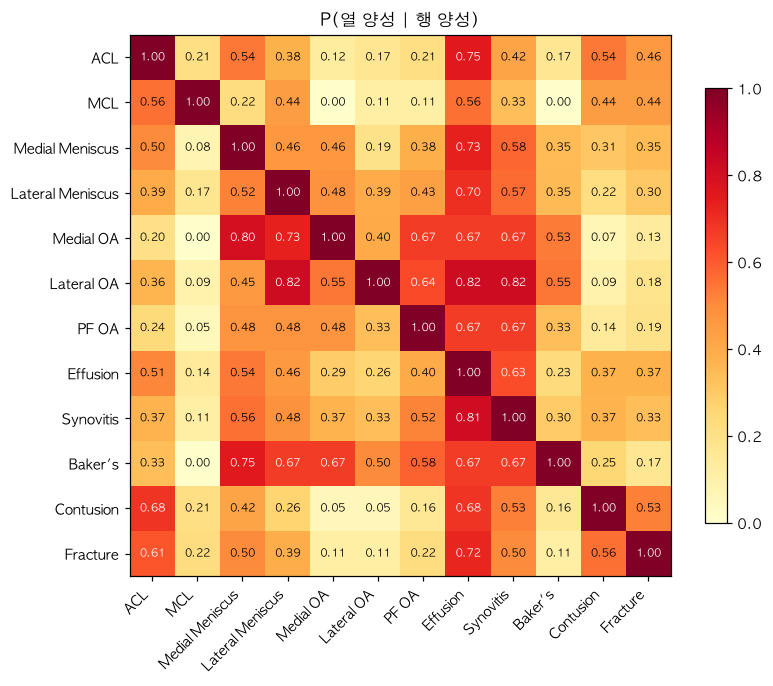

In [7]:
g = gold.fillna(0).astype(int)
co = pd.DataFrame(
    [[((g[a] == 1) & (g[b] == 1)).sum() / max((g[a] == 1).sum(), 1) for b in L] for a in L],
    index=L, columns=L)

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(co.values, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=45, ha='right')
ax.set_yticks(range(len(L))); ax.set_yticklabels(L)
for i in range(len(L)):
    for j in range(len(L)):
        v = co.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=7,
                color='white' if v > 0.6 else 'black')
ax.set_title('P(열 양성 | 행 양성)')
fig.colorbar(im, ax=ax, shrink=0.8)
ax.grid(False)
plt.tight_layout(); plt.show()


In [8]:
# Synovitis 미언급 셀을 Effusion으로 채우는 근거 (디스커션 733932)
e, s = g['Effusion'] == 1, g['Synovitis'] == 1
print(f"P(Synovitis | Effusion)    = {(e & s).sum() / e.sum():.3f}")
print(f"P(Synovitis | no Effusion) = {(~e & s).sum() / (~e).sum():.3f}")
print(f"P(Effusion | Synovitis)    = {(e & s).sum() / s.sum():.3f}")


P(Synovitis | Effusion)    = 0.629
P(Synovitis | no Effusion) = 0.217
P(Effusion | Synovitis)    = 0.815


## 4. 판독문

`train.csv`에만 있고 `test.csv`에는 없다
즉 타깃 생성용이지 모델 입력이 아니다


결측: 0
count    4407.000000
mean     1097.905605
std       693.948925
min        52.000000
25%       587.500000
50%       977.000000
75%      1459.500000
max      4743.000000


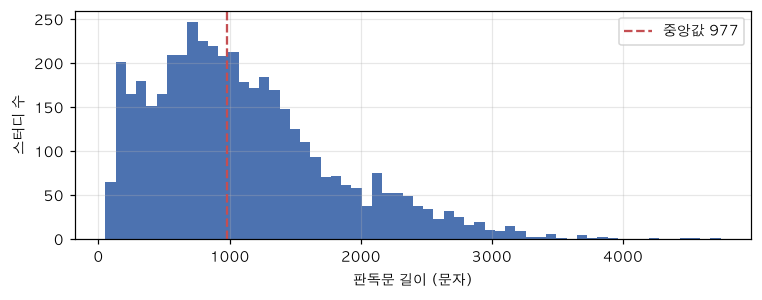

In [9]:
rep = train['Report']
print('결측:', int(rep.isna().sum()))
lens = rep.dropna().str.len()
print(lens.describe().to_string())

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(lens, bins=60, color='#4c72b0')
ax.axvline(lens.median(), color='#c44e52', ls='--', label=f'중앙값 {lens.median():.0f}')
ax.set_xlabel('판독문 길이 (문자)'); ax.set_ylabel('스터디 수'); ax.legend()
plt.tight_layout(); plt.show()


In [10]:
SCRIPTS = {
    '한글': r'[\uac00-\ud7a3]', '키릴': r'[\u0400-\u04ff]',
    '한자/일본어': r'[\u3040-\u30ff\u4e00-\u9fff]', '아랍': r'[\u0600-\u06ff]',
    '그리스': r'[\u0370-\u03ff]', '히브리': r'[\u0590-\u05ff]', '태국': r'[\u0e00-\u0e7f]',
}

def script_of(t):
    if not isinstance(t, str) or not t.strip():
        return '(빈값)'
    c = {k: len(re.findall(p, t)) for k, p in SCRIPTS.items()}
    top = max(c, key=c.get)
    return top if c[top] >= 5 else '라틴 계열'

fam = rep.fillna('').map(script_of)
fam.value_counts().to_frame('건수').assign(비율=lambda d: d['건수'] / len(train))


,건수,비율
Report,,
라틴 계열,3866,0.877241
그리스,321,0.072839
키릴,220,0.049921


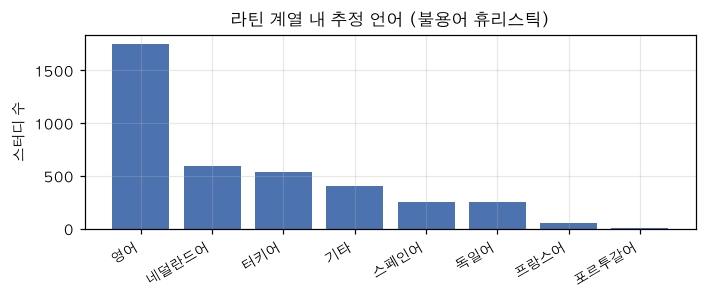

,건수
Report,
영어,1752
네덜란드어,593
터키어,542
기타,401
스페인어,255
독일어,253
프랑스어,58
포르투갈어,12


In [11]:
HINTS = {
    '영어': r'\b(the|and|with|there|normal|tear|joint|knee|effusion)\b',
    '스페인어': r'\b(el|la|los|las|con|sin|rodilla|derecha|izquierda)\b',
    '포르투갈어': r'\b(do|da|dos|das|com|sem|joelho|direito|esquerdo)\b',
    '프랑스어': r'\b(le|les|des|avec|sans|genou|droit|gauche)\b',
    '독일어': r'\b(der|die|das|und|mit|ohne|kniegelenk|rechts|links)\b',
    '이탈리아어': r'\b(il|lo|gli|con|senza|ginocchio|destro|sinistro)\b',
    '터키어': r'\b(ve|ile|sag|sol|diz|eklem)\b',
    '네덜란드어': r'\b(de|het|een|met|zonder|knie)\b',
}

def latin_lang(t):
    s = {k: len(re.findall(p, t.lower())) for k, p in HINTS.items()}
    top = max(s, key=s.get)
    return top if s[top] >= 2 else '기타'

langs = rep[fam == '라틴 계열'].fillna('').map(latin_lang).value_counts()

fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.bar(langs.index, langs.values, color='#4c72b0')
ax.set_ylabel('스터디 수'); ax.set_title('라틴 계열 내 추정 언어 (불용어 휴리스틱)')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()
langs.to_frame('건수')


In [12]:
# 실제 판독문 샘플 - 언어가 섞인 것을 눈으로 확인
for lang in ['그리스', '키릴', '라틴 계열']:
    idx = fam[fam == lang].index[0]
    print(f'===== {lang} =====')
    print(train.loc[idx, 'Report'][:300].replace(chr(10), ' '))
    print()


===== 그리스 =====
MRI ΑΡΙΣΤΕΡΟΥ ΓΟΝΑΤΟΣ ΤΕΧΝΙΚΗ Η εξέταση έγινε µε ακολουθίες παλµών Τ1, Τ2 me2d και Pd fs. ΕΥΡΗΜΑΤΑ Χωρίς ενδαρθρική συλλογή υγρού. Ο οστικός µυελός ελέγχεται εντός του φυσιολογικού. Χωρίς παθολογικά ευρήµατα ελέγχεται ο αρθρικός χόνδρος. Χωρίς ευρήµατα δυσλειτουργίας του εκτατικού µηχανισµού. Εντός 

===== 키릴 =====
МР находка: МР данни за ставен излив. Костите, формиращи дясната коляно са със непроменена структура. Малък костномозъчен едем локализиран в медиалния кондил на тибията.  Артикулиращият хрущял на фемура и тибията е изтънен от медиалната страна на ставата. Няма МР данни за руптура на предната кръстна

===== 라틴 계열 =====
Técnica: RMN de la rodilla. Resultados: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorotibial medial. Derrame. . Impresión: Rotura de menisco interno. Signo de necrosis avascular subcondral en el cóndilo femoral medial. Artrosis femorot



## 5. 시리즈 메타데이터


count    4407.000000
mean        5.530066
std         1.393826
min         3.000000
25%         5.000000
50%         5.000000
75%         6.000000
max        14.000000


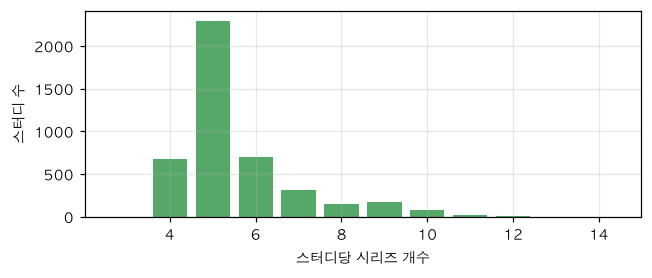

In [13]:
per_study = tr_series.groupby('StudyInstanceUID').size()
print(per_study.describe().to_string())

fig, ax = plt.subplots(figsize=(6, 2.6))
vc = per_study.value_counts().sort_index()
ax.bar(vc.index, vc.values, color='#55a868')
ax.set_xlabel('스터디당 시리즈 개수'); ax.set_ylabel('스터디 수')
plt.tight_layout(); plt.show()


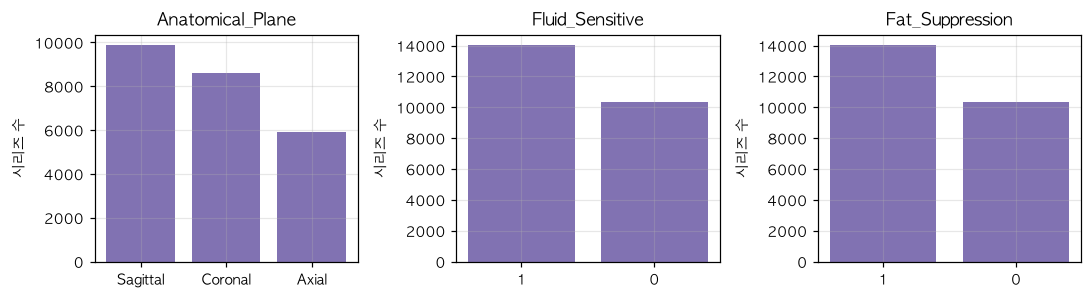

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, col in zip(axes, ['Anatomical_Plane', 'Fluid_Sensitive', 'Fat_Suppression']):
    vc = tr_series[col].value_counts(dropna=False)
    ax.bar(vc.index.astype(str), vc.values, color='#8172b2')
    ax.set_title(col); ax.set_ylabel('시리즈 수')
plt.tight_layout(); plt.show()


### Fluid_Sensitive 와 Fat_Suppression 이 같은 컬럼인가

디스커션에서 두 컬럼이 동일하다는 지적이 있었다
직접 확인한다


In [15]:
same = (tr_series['Fluid_Sensitive'] == tr_series['Fat_Suppression']).sum()
print(f'일치: {same:,} / {len(tr_series):,}  ({same/len(tr_series)*100:.1f}%)')
pd.crosstab(tr_series['Fluid_Sensitive'], tr_series['Fat_Suppression'])


일치: 24,371 / 24,371  (100.0%)


Fat_Suppression,0,1
Fluid_Sensitive,,
0,10361,0
1,0,14010


In [16]:
pd.crosstab(tr_series['Anatomical_Plane'], tr_series['Fluid_Sensitive'])


Fluid_Sensitive,0,1
Anatomical_Plane,,
Axial,1179,4719
Coronal,3985,4624
Sagittal,5197,4667


In [17]:
# 스터디별 시퀀스 커버리지 - 결측 분기가 필요한가
grp = tr_series.groupby('StudyInstanceUID')
cov = pd.DataFrame({
    'Sagittal': grp['Anatomical_Plane'].apply(lambda s: (s == 'Sagittal').any()),
    'Coronal': grp['Anatomical_Plane'].apply(lambda s: (s == 'Coronal').any()),
    'Axial': grp['Anatomical_Plane'].apply(lambda s: (s == 'Axial').any()),
    'FluidSensitive': grp['Fluid_Sensitive'].apply(lambda s: (s == 1).any()),
})
cov.mean().to_frame('보유 비율')


,보유 비율
Sagittal,1.0
Coronal,1.0
Axial,1.0
FluidSensitive,1.0


## 6. 정합성 체크


In [18]:
checks = {
    'train.csv 스터디 == train_series.csv 스터디':
        set(train.StudyInstanceUID) == set(tr_series.StudyInstanceUID),
    'train 스터디 UID 중복 없음': train.StudyInstanceUID.is_unique,
    'sample_submission 컬럼 == config.LABELS': list(sub.columns[1:]) == L,
    'test.csv 스터디 == sample_submission 스터디':
        set(test.StudyInstanceUID) == set(sub.StudyInstanceUID),
    'train/test 스터디 겹침 없음':
        len(set(train.StudyInstanceUID) & set(test.StudyInstanceUID)) == 0,
}
pd.Series(checks).map(lambda v: 'OK' if v else '불일치').to_frame('결과')


,결과
train.csv 스터디 == train_series.csv 스터디,OK
train 스터디 UID 중복 없음,OK
sample_submission 컬럼 == config.LABELS,OK
test.csv 스터디 == sample_submission 스터디,OK
train/test 스터디 겹침 없음,OK


## 7. 모델링 시사점

1. **레이블을 먼저 만들어야 한다** - gold 58건으로는 학습이 불가능하다
   판독문에서 12개 타깃을 뽑는 것이 1단계이고 그 품질이 성능의 천장이다
2. **판독문은 다국어다** - 영어가 40%뿐이라 언어별 정규식은 현실성이 낮다
   공개 측정으로 regex 0.8136 vs LLM 0.8780
3. **"언급 없음"을 음성으로 뭉개지 말 것** - 0.5로 두고 손실에서 마스킹한다
   Synovitis는 미언급이 84%다
4. **58건 gold는 검증 전용** - 학습에 넣기엔 너무 적다
5. **CV는 스터디 단위 분할** - 스터디가 곧 1인 1검사다
6. **`Fat_Suppression`은 버려도 된다** - `Fluid_Sensitive`와 완전 중복이다
7. **시퀀스 결측 분기가 필요 없다** - 모든 스터디가 3개 평면을 다 갖는다
